In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.grid import Grid
from src.elementary_solutions import SourceSink, Vortex, Doublet, UniformFlow
from src.superposition import Superposition, DoubletFreestream, DoubletVortexFreestream

In [2]:
nx, ny = 50, 50
x_start, x_end = -2.0, 2.0
y_start, y_end = -1.0, 1.0

grid = Grid(x_start=x_start, x_end=x_end, y_start=y_start, y_end=y_end, nx=nx, ny=ny)

In [3]:
kappa = 1.0
x_doublet, y_doublet = 0.0, 0.0

doublet = Doublet(strength=kappa, xd=x_doublet, yd=y_doublet)

In [4]:
u_inf = 1.0

uniform_flow = UniformFlow(U_inf=u_inf)

In [5]:
doublet_freestream = DoubletFreestream(doublet, uniform_flow)

In [6]:
u, v = doublet_freestream.velocity_field(grid)
psi = doublet_freestream.stream_function(grid)
R = doublet_freestream.radius()

x_stagn1, y_stagn1, x_stagn2, y_stagn2 = doublet_freestream.stagnation_point()

Text(0.5, 1.0, 'Cylinder Flow')

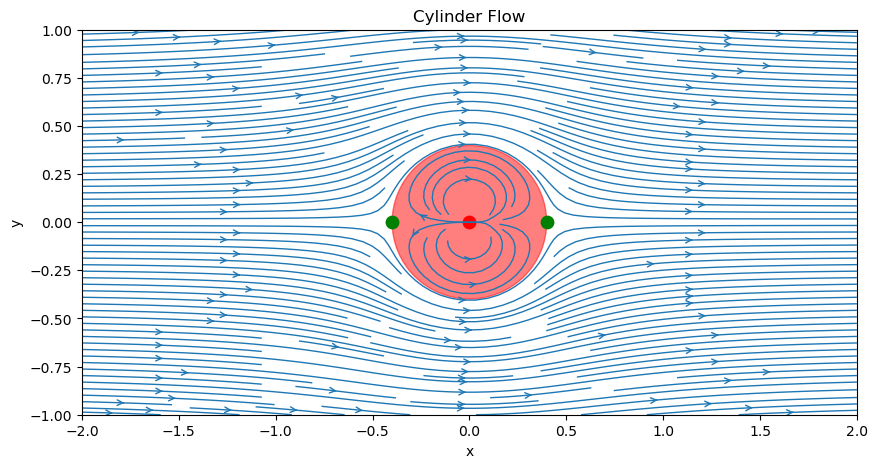

In [7]:
width = 10
height = (y_end - y_start) / (x_end - x_start) * width

fig, ax = plt.subplots(figsize=(width, height))
ax.streamplot(grid.X, grid.Y, u, v, density=2, linewidth=1, arrowsize=1, arrowstyle='->')
ax.scatter(x_doublet, y_doublet, c='r', s=80, marker='o')

circle = plt.Circle((0,0), radius=R, color='r', alpha=0.5)
ax.add_patch(circle)

ax.scatter([x_stagn1, x_stagn2], [y_stagn1, y_stagn2], c='g', s=80, marker='o')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(x_start, x_end)
ax.set_ylim(y_start, y_end)
ax.set_title('Cylinder Flow')


In [8]:
gamma = 4.0                      # strength of the vortex
x_vortex, y_vortex = 0.0, 0.0    # location of the vortex

vortex = Vortex(x=x_vortex, y=y_vortex, gamma=gamma)

In [9]:
u_vortex, v_vortex = vortex.velocity_field(grid)
psi_vortex = vortex.stream_function(grid)

In [10]:
doublet_vortex_freestream = DoubletVortexFreestream(doublet, vortex, uniform_flow)

In [11]:
u, v = doublet_vortex_freestream.velocity_field(grid)
psi = doublet_vortex_freestream.stream_function(grid)

In [12]:
R = doublet_vortex_freestream.radius()

# calculate the stagnation points
x_stagn1, y_stagn1, x_stagn2, y_stagn2 = doublet_vortex_freestream.stagnation_point()

Text(0.5, 1.0, 'Doublet + Vortex + Freestream Solution Streamline')

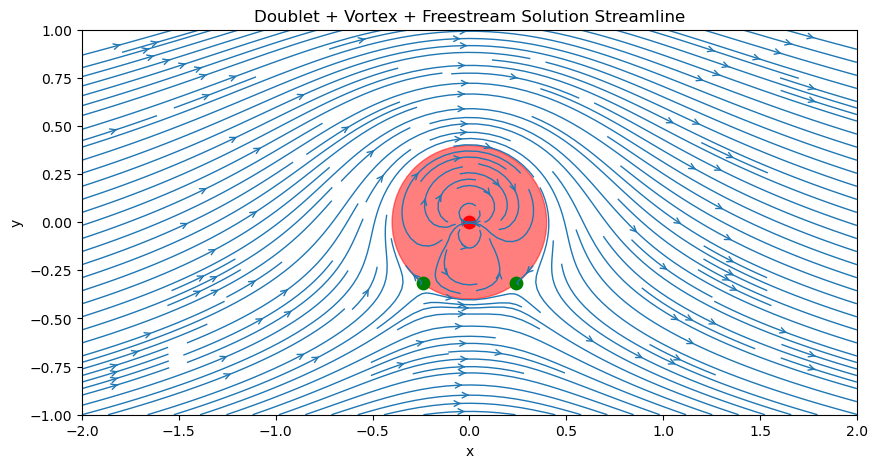

In [13]:
width = 10
height = (y_end - y_start) / (x_end - x_start) * width

fig, ax = plt.subplots(figsize=(width, height))
ax.streamplot(grid.X, grid.Y, u, v, density=2, linewidth=1, arrowsize=1, arrowstyle='->')
ax.scatter(x_vortex, y_vortex, c='r', s=80, marker='o')

circle = plt.Circle((0, 0), radius=R, color='r', alpha=0.5)
ax.add_patch(circle)

ax.scatter([x_stagn1, x_stagn2], [y_stagn1, y_stagn2], c='g', s=80, marker='o')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(x_start, x_end)
ax.set_ylim(y_start, y_end)
ax.set_title('Doublet + Vortex + Freestream Solution Streamline')

In [14]:
theta = np.linspace(0.0, 2 * np.pi, 100)

cp = doublet_vortex_freestream.surface_pressure_coefficient(theta)

cp_no_vortex = doublet_freestream.surface_pressure_coefficient(theta)

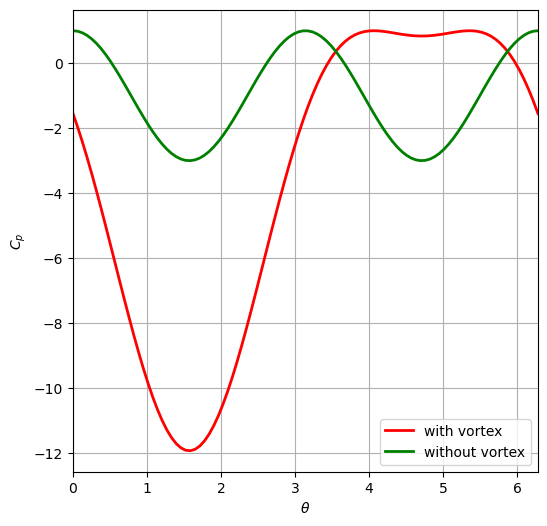

In [20]:
size = 6

fig, ax = plt.subplots(figsize=(size, size))

ax.plot(theta, cp, 
        label='with vortex', color='r', linewidth=2, linestyle='-')
ax.plot(theta, cp_no_vortex,
            label='without vortex', color='g', linewidth=2, linestyle='-')
ax.grid(True)
ax.set_xlim(theta.min(), theta.max())
ax.set_xlabel(r'$\theta$')
ax.set_ylabel('$C_p$')
ax.legend(loc='best')
plt.show()